# InternImage — Vision Foundation Models with Deformable Convolutions (DCNv3)

**Paper:** Wang, W., Dai, J., Chen, Z., Huang, Z., Li, Z., Zhu, X., Hu, X., Lu, T., Lu, L., Li, H., Wang, X., & Qiao, Y. (2023). InternImage: Exploring Large-Scale Vision Foundation Models with Deformable Convolutions. *CVPR 2023*. https://arxiv.org/abs/2211.05778

**Implementation:** `hale_core/nn/vision/cnn/internimage.py`

> InternImage proposes DCNv3 — a separable reformulation of deformable convolution analogous to the ViT attention mechanism — enabling scalable pretraining of large CNN foundation models (up to 3B parameters) that match or exceed ViT-scale transformers.

> 📄 **Paper:** Wang et al. (2023). InternImage: Exploring Large-Scale Vision Foundation Models with Deformable Convolutions. CVPR 2023.
> 🔗 **Link:** <https://arxiv.org/abs/2211.05778>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/internimage.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["stem: 2 × conv 3×3 /2 · LN · GELU → 64"]:::stage
  STEM --> S["4 stages ×[4,4,18,4], widths 64·128·256·512, downsample conv 3×3 /2 between"]:::stage --> GAP["avg pool"]:::block --> OUT
  subgraph BLK["InternImage block"]
    direction LR
    X["x"] --> LN1["LayerNorm"]:::block --> DCN["DCNv3: G groups, K = 3×3 points<br/>offsets Δp and softmax masks m from x"]:::block --> ADD1(("+"))
    X --> ADD1 --> LN2["LayerNorm"]:::block --> MLP["MLP ×4"]:::block --> ADD2(("+"))
    ADD1 --> ADD2
  end
  S -.-> BLK
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
InternImage Backbone:

Input [B, 3, H, W]
  → Stem: 4×4 stride-4 Conv + LayerNorm             [B, C, H/4, W/4]
  → Stage 0: N0 × InternImageBlock                  [B, C,   H/4,  W/4]
  → Downsample (3×3 stride-2 + LN)                  [B, 2C,  H/8,  W/8]
  → Stage 1: N1 × InternImageBlock                  [B, 2C,  H/8,  W/8]
  → Downsample                                       [B, 4C,  H/16, W/16]
  → Stage 2: N2 × InternImageBlock                  [B, 4C,  H/16, W/16]
  → Downsample                                       [B, 8C,  H/32, W/32]
  → Stage 3: N3 × InternImageBlock                  [B, 8C,  H/32, W/32]
  → GlobalAvgPool → [B, 8C]

InternImageBlock (pre-norm Transformer-style):
  x → LayerNorm → DCNv3 → (+x) → LayerNorm → FFN → (+x)

DCNv3 (Separable Deformable Conv):
  vs DCNv2 (O(C²) per group): each group has own projection
  vs DCNv3 (O(C) total):      shared depthwise projection, separate offset/mask per group

DCNv3 Forward:
  x [B,H,W,C] → dw_conv (depthwise BN+GELU, shared)     → x' [B,H,W,C]
             → offset_conv (C → G×K×2 offsets)           → Δp [B,H,W,G,K,2]
             → mask_conv   (C → G×K masks, softmax)      → m  [B,H,W,G,K]
             → grid_sample(x', base+Δp) per group g       → sampled [B,G,K,H,W,C//G]
             → x_sampled * m → proj (C → C)              → output [B,H,W,C]
```

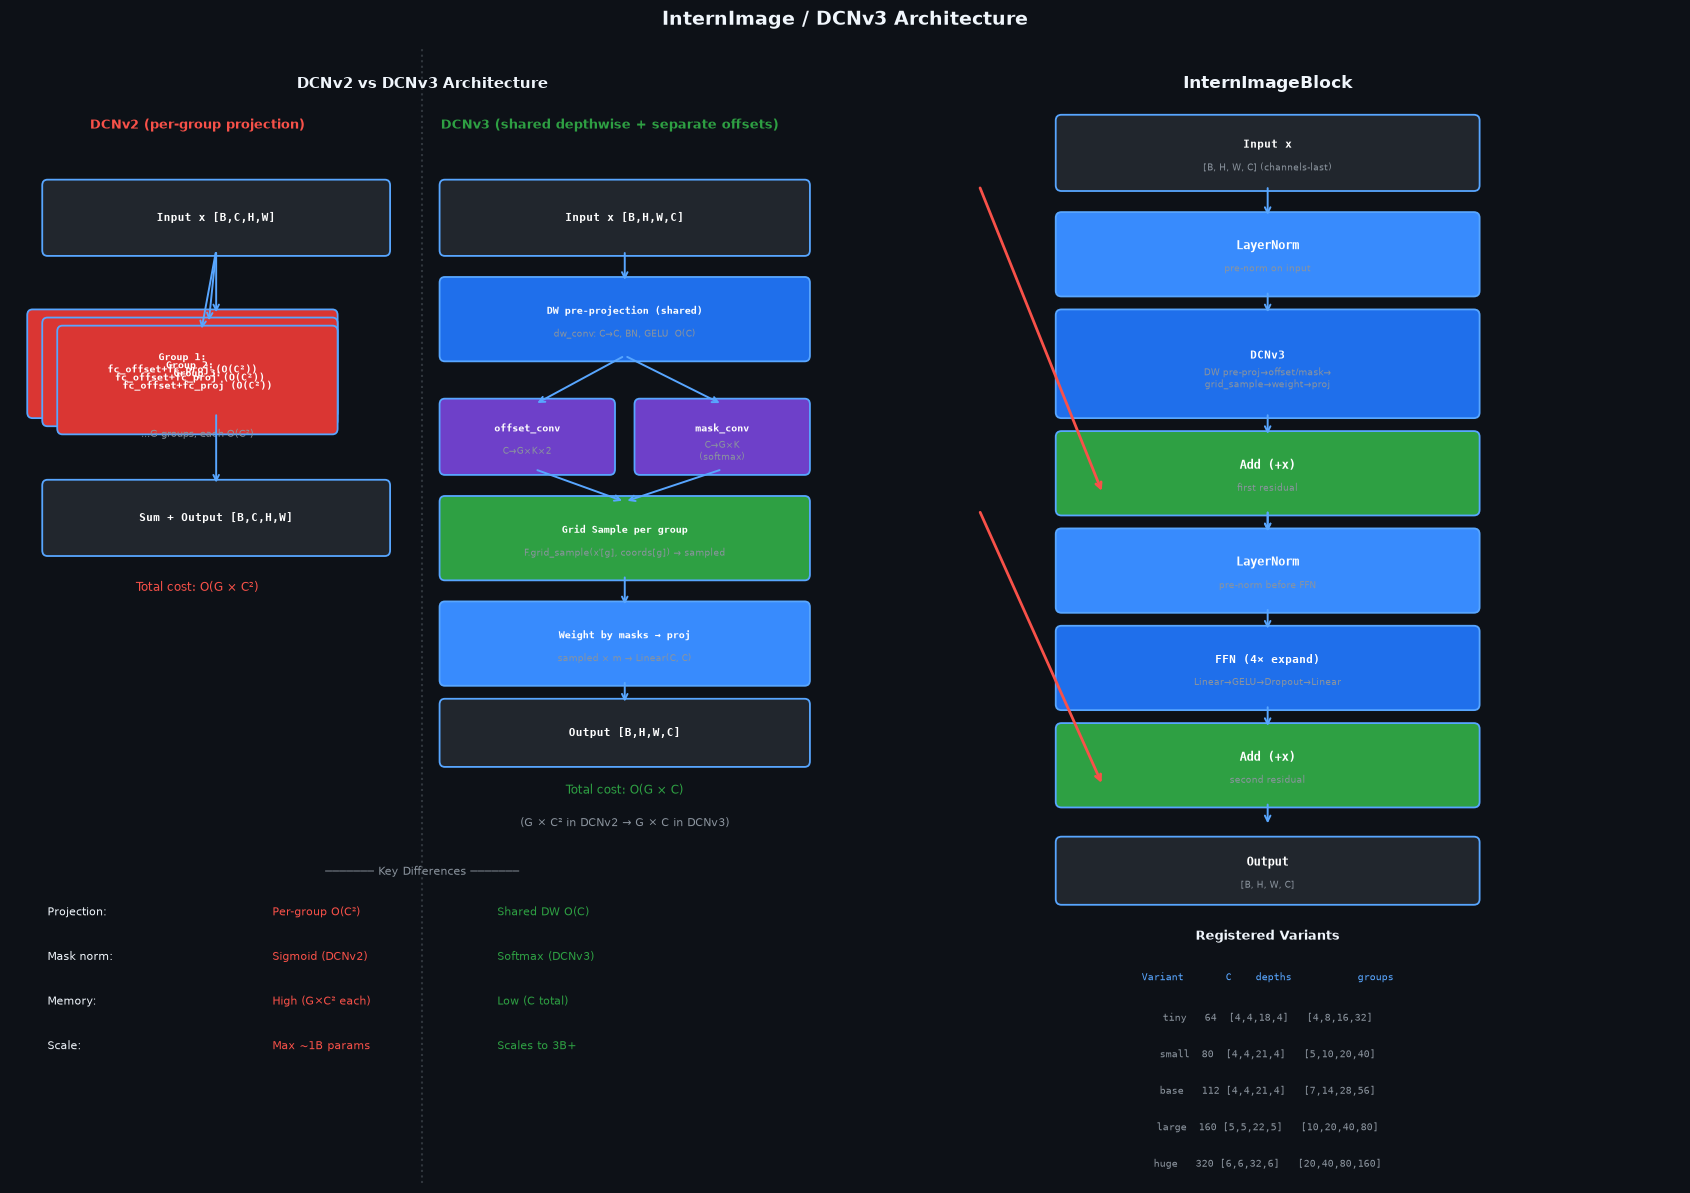

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(17, 12))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#0d1117')
    ax.axis('off')

def box(ax, x, y, w, h, text, sub='', fc='#1f6feb', fs=8.5):
    r = FancyBboxPatch((x,y), w, h, boxstyle='round,pad=0.07',
                        facecolor=fc, edgecolor='#58a6ff', lw=1.3)
    ax.add_patch(r)
    ax.text(x+w/2, y+h/2+(0.1 if sub else 0), text, ha='center', va='center',
            color='white', fontsize=fs, fontweight='bold', fontfamily='monospace')
    if sub:
        ax.text(x+w/2, y+h/2-0.18, sub, ha='center', va='center',
                color='#8b949e', fontsize=6.5)

def arr(ax, x1, y1, x2, y2, c='#58a6ff'):
    ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                arrowprops=dict(arrowstyle='->', color=c, lw=1.4))

# ── LEFT: DCNv3 vs DCNv2 comparison ─────────────────────────────────────────
ax = axes[0]
ax.set_xlim(0, 11)
ax.set_ylim(0, 14)
ax.text(5.5, 13.5, 'DCNv2 vs DCNv3 Architecture', ha='center',
        color='#f0f6fc', fontsize=11, fontweight='bold')

ax.text(2.5, 13.0, 'DCNv2 (per-group projection)', ha='center',
        color='#f85149', fontsize=9, fontweight='bold')
ax.text(8.0, 13.0, 'DCNv3 (shared depthwise + separate offsets)', ha='center',
        color='#2ea043', fontsize=9, fontweight='bold')
ax.axvline(5.5, color='#30363d', lw=1.5, linestyle=':')

# DCNv2
box(ax, 0.5, 11.5, 4.5, 0.8, 'Input x [B,C,H,W]', '', fc='#21262d', fs=8)
for g in range(3):
    gy = 9.5 - g*0.1
    box(ax, 0.3+g*0.2, gy, 4.0-g*0.2, 1.2, f'Group {g+1}:\nfc_offset+fc_proj (O(C²))',
        '', fc='#da3633', fs=7)
    arr(ax, 2.75, 11.5, 2.75-g*0.1, gy+1.2)
ax.text(2.5, 9.2, '...G groups, each O(C²)', ha='center', color='#8b949e', fontsize=7.5)
box(ax, 0.5, 7.8, 4.5, 0.8, 'Sum + Output [B,C,H,W]', '', fc='#21262d', fs=8)
arr(ax, 2.75, 9.5, 2.75, 8.6)
ax.text(2.5, 7.3, 'Total cost: O(G × C²)', ha='center', color='#f85149', fontsize=8.5)

# DCNv3
box(ax, 5.8, 11.5, 4.8, 0.8, 'Input x [B,H,W,C]', '', fc='#21262d', fs=8)

box(ax, 5.8, 10.2, 4.8, 0.9, 'DW pre-projection (shared)',
    'dw_conv: C→C, BN, GELU  O(C)', fc='#1f6feb', fs=7.5)
arr(ax, 8.2, 11.5, 8.2, 11.1)

# branch to offsets and masks
box(ax, 5.8, 8.8, 2.2, 0.8, 'offset_conv', 'C→G×K×2', fc='#6e40c9', fs=7.5)
box(ax, 8.4, 8.8, 2.2, 0.8, 'mask_conv', 'C→G×K\n(softmax)', fc='#6e40c9', fs=7.5)
arr(ax, 8.2, 10.2, 7.0, 9.6)
arr(ax, 8.2, 10.2, 9.5, 9.6)

box(ax, 5.8, 7.5, 4.8, 0.9, 'Grid Sample per group',
    'F.grid_sample(x\'[g], coords[g]) → sampled', fc='#2ea043', fs=7.5)
arr(ax, 7.0, 8.8, 8.2, 8.4)
arr(ax, 9.5, 8.8, 8.2, 8.4)

box(ax, 5.8, 6.2, 4.8, 0.9, 'Weight by masks → proj',
    'sampled × m → Linear(C, C)', fc='#388bfd', fs=7.5)
arr(ax, 8.2, 7.5, 8.2, 7.1)

box(ax, 5.8, 5.2, 4.8, 0.7, 'Output [B,H,W,C]', '', fc='#21262d', fs=8)
arr(ax, 8.2, 6.2, 8.2, 5.9)
ax.text(8.2, 4.8, 'Total cost: O(G × C)', ha='center', color='#2ea043', fontsize=8.5)
ax.text(8.2, 4.4, '(G × C² in DCNv2 → G × C in DCNv3)', ha='center', color='#8b949e', fontsize=8)

# Bottom comparison table
ax.text(5.5, 3.8, '─────── Key Differences ───────', ha='center', color='#8b949e', fontsize=8)
rows = [
    ('Projection',  'Per-group O(C²)',    'Shared DW O(C)'),
    ('Mask norm',   'Sigmoid (DCNv2)',     'Softmax (DCNv3)'),
    ('Memory',      'High (G×C² each)',   'Low (C total)'),
    ('Scale',       'Max ~1B params',      'Scales to 3B+'),
]
for i, (prop, v2, v3) in enumerate(rows):
    ax.text(0.5, 3.3 - i*0.55, f'{prop}:', color='#f0f6fc', fontsize=8)
    ax.text(3.5, 3.3 - i*0.55, v2, color='#f85149', fontsize=8)
    ax.text(6.5, 3.3 - i*0.55, v3, color='#2ea043', fontsize=8)

# ── RIGHT: InternImageBlock detail ───────────────────────────────────────────
ax = axes[1]
ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.text(5, 13.5, 'InternImageBlock', ha='center', color='#f0f6fc',
        fontsize=12, fontweight='bold')

box(ax, 2.5, 12.3, 5, 0.8, 'Input x', '[B, H, W, C] (channels-last)', fc='#21262d', fs=8)

box(ax, 2.5, 11.0, 5, 0.9, 'LayerNorm', 'pre-norm on input', fc='#388bfd')
arr(ax, 5, 12.3, 5, 11.9)
box(ax, 2.5, 9.5,  5, 1.2, 'DCNv3', 'DW pre-proj→offset/mask→\ngrid_sample→weight→proj', fc='#1f6feb', fs=8)
arr(ax, 5, 11.0, 5, 10.7)
box(ax, 2.5, 8.3,  5, 0.9, 'Add (+x)', 'first residual', fc='#2ea043')
arr(ax, 5, 9.5, 5, 9.2)
ax.annotate('', xy=(3.0, 8.5), xytext=(1.5, 12.3),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=2.0,
                            connectionstyle='arc3,rad=0.0'))
arr(ax, 5, 8.3, 5, 8.0)

box(ax, 2.5, 7.1,  5, 0.9, 'LayerNorm', 'pre-norm before FFN', fc='#388bfd')
arr(ax, 5, 8.3, 5, 8.0)
box(ax, 2.5, 5.9,  5, 0.9, 'FFN (4× expand)', 'Linear→GELU→Dropout→Linear', fc='#1f6feb', fs=8)
arr(ax, 5, 7.1, 5, 6.8)
box(ax, 2.5, 4.7,  5, 0.9, 'Add (+x)', 'second residual', fc='#2ea043')
arr(ax, 5, 5.9, 5, 5.6)
ax.annotate('', xy=(3.0, 4.9), xytext=(1.5, 8.3),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=2.0,
                            connectionstyle='arc3,rad=0.0'))
arr(ax, 5, 4.7, 5, 4.4)
box(ax, 2.5, 3.5,  5, 0.7, 'Output', '[B, H, W, C]', fc='#21262d')

# variant table
ax.text(5, 3.0, 'Registered Variants', ha='center', color='#f0f6fc', fontsize=9, fontweight='bold')
ax.text(5, 2.5, 'Variant       C    depths           groups', ha='center',
        color='#58a6ff', fontsize=7.5, fontfamily='monospace')
rows = [
    'tiny   64  [4,4,18,4]   [4,8,16,32]',
    'small  80  [4,4,21,4]   [5,10,20,40]',
    'base   112 [4,4,21,4]   [7,14,28,56]',
    'large  160 [5,5,22,5]   [10,20,40,80]',
    'huge   320 [6,6,32,6]   [20,40,80,160]',
]
for i, r in enumerate(rows):
    ax.text(5, 2.0 - i*0.45, r, ha='center', color='#8b949e',
            fontsize=7.5, fontfamily='monospace')

plt.suptitle('InternImage / DCNv3 Architecture', fontsize=14, color='#f0f6fc',
             fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. The CNN Scaling Problem
ViT-style transformers (ViT, Swin, DeiT) achieved strong results at large scales by leveraging global self-attention. Could CNNs also scale to foundation-model size while maintaining their inductive biases (translation equivariance, spatial locality)? The challenge: DCNv2's per-group projection is O(G × C²), making it too expensive to scale.

### 2. DCNv3 — Separable Deformable Convolution
DCNv3 redesigns deformable convolution as a separable operation:
- **Shared depthwise pre-projection**: A single depthwise conv processes all channels (O(C) cost). This is *shared* across all G groups.
- **Per-group offset prediction**: Each group has its own lightweight offset predictor for K sampling points. The G groups learn diverse receptive fields.
- **Softmax masking** (DCNv3) vs sigmoid masking (DCNv2): Softmax normalises across the K sampling points, ensuring the weights sum to 1. This improves stability and interpretability.

**Analogy to ViT attention**:  
ViT: Q×K (O(N²C)) + V projection (O(C²)) per head  
DCNv3: offset prediction (O(GKC)) + shared DW (O(C)) per group  
Both use multi-group/head factorisation to reduce cost.

### 3. InternImageBlock — Pre-Norm Transformer Style
The block follows the ViT post-norm-free design:
```
x = x + DCNv3(LN(x))   # spatial mixing (like attention)
x = x + FFN(LN(x))     # channel mixing (like MLP)
```
This structure allows stacking many blocks without gradient vanishing, mirrors ViT's architecture, and enables joint pre-training with transformers.

### 4. Adaptive Receptive Field
Unlike fixed-grid convolutions, DCNv3 learns WHERE to look. For each output position, each group learns K offset points: the network can sample the car's wheels and roof for a 'car' feature, or adjacent characters for a text feature. Different groups learn complementary sampling patterns.

### 5. Pure PyTorch Implementation (No CUDA Extension)
The official InternImage requires a compiled CUDA extension (`dcnv3_ops`). This implementation uses `F.grid_sample` which is a standard PyTorch op with bilinear interpolation, providing identical mathematical behaviour with full autograd support — at the cost of slightly lower throughput vs the CUDA kernel.

## Component Walkthrough

### `DCNv3.__init__` (lines 96–140 in `internimage.py`)
```python
# Shared depthwise pre-projection (O(C) — not per-group)
self.dw_conv = nn.Sequential(
    nn.Conv2d(channels, channels, dw_kernel, groups=channels, bias=False),  # depthwise
    nn.BatchNorm2d(channels),
    nn.GELU(),
)
# Per-group offset: G × K × 2 channels total
self.offset_conv = nn.Linear(channels, groups * self.K * 2)
nn.init.zeros_(self.offset_conv.weight)  # start as regular grid
# Per-group mask: G × K channels, softmax normalised across K
self.mask_conv   = nn.Linear(channels, groups * self.K)
# Output projection
self.proj = nn.Linear(channels, channels)
```

### `DCNv3._deformable_sample` (lines 195–285)
```python
# Create base sampling grid [1, Hs, Ws, 1, 1, 2]
grid_base = torch.stack([grid_x, grid_y], dim=-1).unsqueeze(0).unsqueeze(3).unsqueeze(4)
# Regular k×k kernel offsets [1, 1, 1, 1, K, 2]
base_k_norm = base_k.view(1, 1, 1, 1, K, 2)  # K grid points, normalised
# Learned offsets [B, Hs, Ws, G, K, 2]
# grid_base + base_k_norm broadcasts to [1, Hs, Ws, 1, K, 2]
# + off_norm [B, Hs, Ws, G, K, 2] → [B, Hs, Ws, G, K, 2]
coords = (grid_base + base_k_norm + off_norm).clamp(-1, 1)

# For each group g, sample input at group-specific offsets
for g in range(G):
    cg = coords[:, :, :, g, :, :].contiguous()  # [B, Hs, Ws, K, 2]
    cg = cg.permute(0, 3, 1, 2, 4).reshape(B*K, Hs, Ws, 2)  # [B*K, Hs, Ws, 2]
    xg = x_groups[:, g].unsqueeze(1).expand(-1, K, -1, -1, -1).reshape(B*K, Cg, H, W)
    out_g = F.grid_sample(xg, cg, mode='bilinear', align_corners=False)  # [B*K, Cg, Hs, Ws]
    # reshape → [B, Cg, Hs, Ws, K] and accumulate
```

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/internimage.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/internimage.py</code></summary>

```text
InternImage — DCNv3-based Vision Backbone (Wang et al. 2022)
=============================================================

Reference: "InternImage: Exploring Large-Scale Vision Foundation Models
           with Deformable Convolutions"
           https://arxiv.org/abs/2211.05778

Key Innovation: DCNv3 (Deformable Convolution v3)
--------------------------------------------------
DCNv3 makes deformable convolution efficient and scalable by redesigning it
as a SEPARABLE operation, analogous to the ViT attention mechanism:

Standard DCNv2 (each of G groups has its own fully-connected projection):
  - Output = Σ_g Σ_k w_g,k · x(p + Δp_g,k) · m_g,k
  - Projection per group: O(C²) cost

DCNv3 (shared depthwise projection, separate per-group offsets/masks):
  - Depthwise over all channels first (shared, O(C) cost)
  - Then per-group offset/mask prediction (O(C) total, not O(C²))
  - Output = Σ_g Σ_k (W_proj · x(p + Δp_g,k)) · m_g,k
  - This makes DCNv3 as scalable as ViT attention

Deformable Convolution Sampling:
  Instead of a fixed k×k grid, DCNv3 learns offsets Δp_g,k for each
  of K sampling points in each of G groups. The network learns WHERE
  to look in the input feature map for each output location.
  - Input position p: any spatial location in the feature map
  - Learned offset Δp_g,k: 2D offset for sampling point k in group g
  - Sampling: x(p + Δp_g,k) via bilinear interpolation
  - Modulation mask m_g,k: scalar in [0,1] weighting each sample point

  This gives adaptive receptive fields: for cars, the network might learn
  to aggregate features from the wheels and roof; for text, each character
  might focus on adjacent strokes.

DCNv3 Layer Implementation (without the C extension):
  We implement DCNv3 using F.grid_sample (bilinear interpolation) on
  GPU-computed offset coordinates. This is slightly slower than the CUDA
  kernel but avoids the build dependency on DCNv3's custom ops.

Architecture
------------
  Stem: 4×4 stride-4 conv (patch-like), LayerNorm
  4 stages, each with:
    - N InternImage blocks (DCNv3 + FFN)
    - Downsampling layer between stages (2×2 stride-2 conv, LayerNorm)

  InternImageBlock:
    input → LayerNorm → DCNv3 → LayerNorm → FFN → residual add

  FFN: Linear → GELU → Linear (4× expand)

Registered variants:
  internimage_tiny:  C=64,  depths=[4,4,18,4],  groups=[4,8,16,32]
  internimage_small: C=80,  depths=[4,4,21,4],  groups=[5,10,20,40]
  internimage_base:  C=112, depths=[4,4,21,4],  groups=[7,14,28,56]
  internimage_large: C=160, depths=[5,5,22,5],  groups=[10,20,40,80]
  internimage_huge:  C=320, depths=[6,6,32,6],  groups=[20,40,80,160]
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/internimage.py`, definition by definition

**`DCNv3`** - Deformable Convolution v3 — separable formulation.

In [5]:
class DCNv3(nn.Module):
    """Deformable Convolution v3 — separable formulation.

    Implements DCNv3 using torch.nn.functional.grid_sample as the
    bilinear interpolation backend. This avoids the custom CUDA kernel
    dependency while preserving the mathematical equivalence.

    For production deployments with the original InternImage CUDA kernel,
    replace the sample_with_offsets() call below with the custom op.

    Args:
        channels:    Feature channel count (total, split across groups).
        kernel_size: Sampling grid side length k; total K = k² sampling points.
        stride:      Spatial stride (1 = same-size, 2 = downsample).
        groups:      Number of deformable groups (must divide channels evenly).
        offset_scale: Multiplier for learned offsets (controls receptive field).
        dw_kernel:   Kernel size for the depthwise pre-projection.
    """

    def __init__(
        self,
        channels:     int,
        kernel_size:  int   = 3,
        stride:       int   = 1,
        groups:       int   = 4,
        offset_scale: float = 1.0,
        dw_kernel:    int   = 3,
    ) -> None:
        super().__init__()
        assert channels % groups == 0, "channels must be divisible by groups"

        self.channels     = channels
        self.kernel_size  = kernel_size
        self.stride       = stride
        self.groups       = groups
        self.offset_scale = offset_scale
        self.K            = kernel_size * kernel_size  # total sampling points

        # Depthwise pre-projection (shared across groups, O(C) cost)
        self.dw_conv = nn.Sequential(
            nn.Conv2d(channels, channels, dw_kernel,
                      stride=1, padding=dw_kernel // 2, groups=channels, bias=False),
            nn.BatchNorm2d(channels),
            nn.GELU(),
        )

        # Per-group offset + mask prediction:
        # For each output location: G groups × K points × 2 offsets + G×K masks
        self.offset_mask_proj = nn.Linear(channels, groups * self.K * 3)
        # Bias init: zero offsets, positive mask logits → mild deformation at start
        nn.init.zeros_(self.offset_mask_proj.weight)
        nn.init.constant_(self.offset_mask_proj.bias, 0.0)

        # Output projection: per-group → full channels
        self.output_proj = nn.Linear(channels, channels)

        self._init_base_grid()

    def _init_base_grid(self) -> None:
        """Pre-compute the regular k×k grid of sampling offsets (centre = 0).

        Base grid: for a 3×3 kernel → 9 points at offsets (-1,-1), (-1,0), ...
        These are added to the learned Δp to get final sampling positions.
        """
        ks = self.kernel_size
        # Base offsets: [K, 2] in (y, x) order
        ys = torch.arange(ks, dtype=torch.float32) - ks // 2
        xs = torch.arange(ks, dtype=torch.float32) - ks // 2
        grid_y, grid_x = torch.meshgrid(ys, xs, indexing="ij")
        base_grid = torch.stack([grid_x, grid_y], dim=-1).view(-1, 2)  # [K, 2]
        self.register_buffer("base_grid", base_grid, persistent=False)  # [K, 2]

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Apply DCNv3 deformable convolution.

        Args:
            x: [B, C, H, W] input features.

        Returns:
            [B, C, H_out, W_out] output features.
            H_out = H/stride, W_out = W/stride.
        """
        B, C, H, W = x.shape
        Hs = math.ceil(H / self.stride)
        Ws = math.ceil(W / self.stride)

        # ── Step 1: Depthwise pre-projection ────────────────────────────────
        # Shared feature aggregation before per-group deformable sampling
        x_dw = self.dw_conv(x)  # [B, C, H, W]

        # Pool to output resolution if stride > 1
        if self.stride > 1:
            x_pool = F.avg_pool2d(x_dw, kernel_size=self.stride, stride=self.stride)
        else:
            x_pool = x_dw  # [B, C, Hs, Ws]

        # ── Step 2: Predict offsets and modulation masks ─────────────────────
        # Reshape spatial dims to token sequence for linear proj
        x_flat = x_pool.permute(0, 2, 3, 1).reshape(B * Hs * Ws, C)
        offset_mask = self.offset_mask_proj(x_flat)           # [B*Hs*Ws, G*K*3]
        offset_mask = offset_mask.view(B, Hs, Ws, self.groups, self.K, 3)

        # Split into offsets (2D) and masks (1D)
        offsets = offset_mask[..., :2] * self.offset_scale    # [B, Hs, Ws, G, K, 2]
        masks   = torch.sigmoid(offset_mask[..., 2])          # [B, Hs, Ws, G, K]

        # ── Step 3: Bilinear sampling at offset positions ────────────────────
        x_sampled = self._deformable_sample(x, offsets, Hs, Ws)
        # x_sampled: [B, G, K, Hs, Ws, C//G]

        # ── Step 4: Apply modulation masks and aggregate ─────────────────────
        # masks: [B, Hs, Ws, G, K] → [B, G, K, Hs, Ws, 1]
        masks  = masks.permute(0, 3, 4, 1, 2).unsqueeze(-1)
        out    = (x_sampled * masks).sum(dim=2)                # [B, G, Hs, Ws, C//G]
        out    = out.permute(0, 2, 3, 1, 4).reshape(B, Hs, Ws, C)

        # ── Step 5: Output projection ─────────────────────────────────────────
        out = self.output_proj(out)                            # [B, Hs, Ws, C]
        return out.permute(0, 3, 1, 2)                        # [B, C, Hs, Ws]

    def _deformable_sample(
        self,
        x:       torch.Tensor,    # [B, C, H, W]
        offsets: torch.Tensor,    # [B, Hs, Ws, G, K, 2]
        Hs:      int,
        Ws:      int,
    ) -> torch.Tensor:
        """Sample x at offset positions using bilinear interpolation.

        Returns:
            [B, G, K, Hs, Ws, C//G]
        """
        B, C, H, W = x.shape
        G  = self.groups
        K  = self.K
        Cg = C // G

        # Compute sampling grid in normalised [-1, 1] coordinates
        # Base grid: [K, 2] regular k×k grid → broadcast over [B, Hs, Ws, K]
        # offsets:   [B, Hs, Ws, G, K, 2]

        # Create regular grid for output positions.
        # Shape must broadcast with offsets [B, Hs, Ws, G, K, 2], so we add
        # both a G-dim and a K-dim: [1, Hs, Ws, 1, 1, 2].
        ys = torch.linspace(-1 + 1 / Hs, 1 - 1 / Hs, Hs, device=x.device)
        xs = torch.linspace(-1 + 1 / Ws, 1 - 1 / Ws, Ws, device=x.device)
        grid_y, grid_x = torch.meshgrid(ys, xs, indexing="ij")
        grid_base = torch.stack([grid_x, grid_y], dim=-1)      # [Hs, Ws, 2]
        grid_base = grid_base.unsqueeze(0).unsqueeze(3).unsqueeze(4)  # [1, Hs, Ws, 1, 1, 2]

        # Base kernel offsets in normalised coordinates [1, 1, 1, 1, K, 2]
        base_k = self.base_grid.to(x.device)                   # [K, 2]
        base_k_norm = base_k.clone()
        base_k_norm[:, 0] /= (W / 2)
        base_k_norm[:, 1] /= (H / 2)
        base_k_norm = base_k_norm.view(1, 1, 1, 1, K, 2)      # [1, 1, 1, 1, K, 2]

        # Learned offsets (normalised by H/W)
        off_norm = offsets.clone()
        off_norm[..., 0] /= (W / 2)
        off_norm[..., 1] /= (H / 2)

        # Per-group sampling coordinates: broadcast [1,Hs,Ws,1,1,2] + [1,1,1,1,K,2]
        # + [B,Hs,Ws,G,K,2] → [B, Hs, Ws, G, K, 2]
        coords = grid_base + base_k_norm + off_norm
        coords = coords.clamp(-1, 1)

        # Sample x for each group separately.
        # Vectorise over K by treating B*K as the batch dimension for grid_sample.
        x_groups = x.reshape(B, G, Cg, H, W)               # [B, G, Cg, H, W]

        sampled = []
        for g in range(G):
            # Expand input along the K axis: [B, K, Cg, H, W] → [B*K, Cg, H, W]
            xg = x_groups[:, g]                             # [B, Cg, H, W]
            xg = xg.unsqueeze(1).expand(-1, K, -1, -1, -1).reshape(B * K, Cg, H, W)

            # Sampling grid for group g: [B, Hs, Ws, K, 2]
            # .contiguous() is needed before reshape because indexing on dim 3 (G)
            # produces a non-contiguous slice.
            cg = coords[:, :, :, g, :, :].contiguous()     # [B, Hs, Ws, K, 2]
            cg = cg.permute(0, 3, 1, 2, 4).reshape(B * K, Hs, Ws, 2)  # [B*K, Hs, Ws, 2]

            out_g = F.grid_sample(xg, cg, mode="bilinear",
                                  align_corners=False, padding_mode="zeros")
            # out_g: [B*K, Cg, Hs, Ws] → [B, K, Cg, Hs, Ws] → [B, Cg, Hs, Ws, K]
            out_g = out_g.reshape(B, K, Cg, Hs, Ws)
            out_g = out_g.permute(0, 2, 3, 4, 1)           # [B, Cg, Hs, Ws, K]
            sampled.append(out_g)

        # Stack groups: [B, G, Cg, Hs, Ws, K]
        out = torch.stack(sampled, dim=1)
        # Rearrange to [B, G, K, Hs, Ws, Cg]
        out = out.permute(0, 1, 5, 3, 4, 2)
        return out

**`InternImageFFN`** - Feed-Forward Network: Linear → GELU → Dropout → Linear → Dropout.

In [6]:
class InternImageFFN(nn.Module):
    """Feed-Forward Network: Linear → GELU → Dropout → Linear → Dropout."""

    def __init__(self, channels: int, expand: int = 4, drop: float = 0.0) -> None:
        super().__init__()
        mid = channels * expand
        self.fc1  = nn.Linear(channels, mid)
        self.act  = nn.GELU()
        self.drop1 = nn.Dropout(drop)
        self.fc2  = nn.Linear(mid, channels)
        self.drop2 = nn.Dropout(drop)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.drop2(self.fc2(self.drop1(self.act(self.fc1(x)))))

**`InternImageBlock`** - Single InternImage transformer block.

In [7]:
class InternImageBlock(nn.Module):
    """Single InternImage transformer block.

    Structure (pre-norm convention):
        x → LN → DCNv3 → x (residual)
        x → LN → FFN   → x (residual)

    Pre-norm stabilises training for large models; same design as ViT.

    Args:
        channels:    Feature channels.
        groups:      DCNv3 deformable groups.
        kernel_size: DCNv3 sampling grid size.
        ffn_expand:  FFN expansion ratio.
        drop:        Dropout for FFN.
        drop_path:   Stochastic depth probability.
    """

    def __init__(
        self,
        channels:    int,
        groups:      int,
        kernel_size: int   = 3,
        ffn_expand:  int   = 4,
        drop:        float = 0.0,
        drop_path:   float = 0.0,
    ) -> None:
        super().__init__()
        self.norm1 = nn.LayerNorm(channels, eps=1e-6)
        self.dcnv3 = DCNv3(channels, kernel_size=kernel_size, groups=groups)
        self.norm2 = nn.LayerNorm(channels, eps=1e-6)
        self.ffn   = InternImageFFN(channels, ffn_expand, drop)
        # Stochastic depth on both branches
        self.drop_path = _DropPath(drop_path) if drop_path > 0.0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W] channels-first
        B, C, H, W = x.shape

        # DCNv3 residual branch (with pre-norm)
        x_ln = x.permute(0, 2, 3, 1)      # → [B, H, W, C] for LayerNorm
        x_ln = self.norm1(x_ln).permute(0, 3, 1, 2)  # → [B, C, H, W]
        x = x + self.drop_path(self.dcnv3(x_ln))

        # FFN residual branch (with pre-norm)
        x_ln = x.permute(0, 2, 3, 1)      # → [B, H, W, C]
        x_ln = self.drop_path(self.ffn(self.norm2(x_ln)))
        x = x + x_ln.permute(0, 3, 1, 2)
        return x

**`_DropPath`** - Stochastic depth: drop entire residual path for a sample.

In [8]:
class _DropPath(nn.Module):
    """Stochastic depth: drop entire residual path for a sample."""
    def __init__(self, drop_prob: float) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        survival = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        noise = torch.empty(shape, device=x.device, dtype=x.dtype).bernoulli_(survival)
        return x * noise.div_(survival)

**`InternImageDownsample`** - Between-stage downsampling: LayerNorm → 3×3 stride-2 conv → double channels.

In [9]:
class InternImageDownsample(nn.Module):
    """Between-stage downsampling: LayerNorm → 3×3 stride-2 conv → double channels."""

    def __init__(self, in_ch: int, out_ch: int) -> None:
        super().__init__()
        self.norm = nn.LayerNorm(in_ch, eps=1e-6)
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=2, padding=1, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W]
        x = x.permute(0, 2, 3, 1)              # → [B, H, W, C]
        x = self.norm(x).permute(0, 3, 1, 2)   # → [B, C, H, W]
        return self.conv(x)

**`InternImageBackbone`** - InternImage hierarchical backbone using DCNv3 operators.

In [10]:
class InternImageBackbone(BaseVisionBackbone):
    """InternImage hierarchical backbone using DCNv3 operators.

    4 stages, each producing a feature map at a different resolution.
    Adaptive receptive fields via deformable convolution.

    Args:
        stem_channels: Initial channel count (C in the paper).
        depths:        Number of InternImageBlock per stage.
        groups:        DCNv3 deformable groups per stage.
        drop_path_rate: Max stochastic depth rate.
        img_size, in_chans, drop_rate: See BaseVisionBackbone.
    """

    arch_name:    str       = "internimage"
    embed_dim:    int       = 0
    feature_dims: list[int] = []

    def __init__(
        self,
        stem_channels:  int,
        depths:         list[int],
        groups:         list[int],
        drop_path_rate: float        = 0.1,
        img_size:       int          = 224,
        in_chans:       int          = 3,
        drop_rate:      float        = 0.0,
        out_indices:    list[int] | None = None,
    ) -> None:
        assert len(depths) == len(groups) == 4, "Need exactly 4 stages"

        # Channel progression: double each stage
        channels = [stem_channels * (2 ** i) for i in range(4)]
        self.feature_dims = channels
        self.embed_dim    = channels[-1]

        super().__init__(img_size=img_size, in_chans=in_chans,
                         drop_rate=drop_rate, out_indices=out_indices)

        # ── Stem: patch-like embedding with 4×4 stride-4 conv ─────────────────
        # Conv and LayerNorm are separate modules because the LN runs channels-last
        # (see forward). There is deliberately no other stem module: unused parameters
        # never get a gradient and make DistributedDataParallel fail.
        self.stem_conv = nn.Conv2d(in_chans, channels[0], kernel_size=4, stride=4, bias=False)
        self.stem_norm = nn.LayerNorm(channels[0], eps=1e-6)

        # ── Stages ───────────────────────────────────────────────────────────
        total_blocks = sum(depths)
        block_idx    = 0

        self.stages:      nn.ModuleList = nn.ModuleList()
        self.downsamples: nn.ModuleList = nn.ModuleList()

        for i, (n, g) in enumerate(zip(depths, groups)):
            blocks = nn.ModuleList()
            for _ in range(n):
                dp = drop_path_rate * block_idx / max(total_blocks - 1, 1)
                blocks.append(InternImageBlock(
                    channels=channels[i], groups=g,
                    kernel_size=3, ffn_expand=4, drop=0.0, drop_path=dp,
                ))
                block_idx += 1
            self.stages.append(blocks)
            # Downsample between stages (not after last stage)
            if i < 3:
                self.downsamples.append(InternImageDownsample(channels[i], channels[i + 1]))

        # ── Global pooling ────────────────────────────────────────────────────
        self.norm_last = nn.LayerNorm(channels[-1], eps=1e-6)
        self.pool      = nn.AdaptiveAvgPool2d(1)
        self.head_drop = nn.Dropout(drop_rate)

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.LayerNorm, nn.BatchNorm2d)):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        # Stem
        x = self.stem_conv(x)                                  # [B, C, H/4, W/4]
        B, C, H, W = x.shape
        x = x.permute(0, 2, 3, 1)                             # channels-last for LN
        x = self.stem_norm(x).permute(0, 3, 1, 2)            # back to [B, C, H, W]

        feature_maps: list[torch.Tensor] = []

        for i, stage_blocks in enumerate(self.stages):
            for block in stage_blocks:
                x = block(x)
            feature_maps.append(x)

            if i < len(self.downsamples):
                x = self.downsamples[i](x)

        # Normalise final features for pooling
        B, C, H, W = feature_maps[-1].shape
        x_last = feature_maps[-1].permute(0, 2, 3, 1)
        x_last = self.norm_last(x_last).permute(0, 3, 1, 2)

        # Global pooled embedding
        pooled = self.pool(x_last).flatten(1)
        pooled = self.head_drop(pooled)

        # Select requested scales
        indices     = self.out_indices if self.out_indices is not None else list(range(4))
        selected    = [feature_maps[i] for i in indices if i < len(feature_maps)]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=selected,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stages 0..stage."""
        for p in self.stem_conv.parameters():
            p.requires_grad_(False)
        for p in self.stem_norm.parameters():
            p.requires_grad_(False)
        for i, s in enumerate(self.stages):
            if i <= stage:
                for p in s.parameters():
                    p.requires_grad_(False)

**`InternImageTiny`** - InternImage-T: 30M params, fast.

In [11]:
@register_vision_backbone("internimage_tiny")
class InternImageTiny(InternImageBackbone):
    """InternImage-T: 30M params, fast."""
    arch_name = "internimage_tiny"
    def __init__(self, **kwargs):
        super().__init__(stem_channels=64, depths=[4,4,18,4],
                         groups=[4,8,16,32], **kwargs)

**`InternImageSmall`** - InternImage-S: 50M params.

In [12]:
@register_vision_backbone("internimage_small")
class InternImageSmall(InternImageBackbone):
    """InternImage-S: 50M params."""
    arch_name = "internimage_small"
    def __init__(self, **kwargs):
        super().__init__(stem_channels=80, depths=[4,4,21,4],
                         groups=[5,10,20,40], **kwargs)

**`InternImageBase`** - InternImage-B: 97M params.

In [13]:
@register_vision_backbone("internimage_base")
class InternImageBase(InternImageBackbone):
    """InternImage-B: 97M params."""
    arch_name = "internimage_base"
    def __init__(self, **kwargs):
        super().__init__(stem_channels=112, depths=[4,4,21,4],
                         groups=[7,14,28,56], **kwargs)

**`InternImageLarge`** - InternImage-L: 223M params, high accuracy.

In [14]:
@register_vision_backbone("internimage_large")
class InternImageLarge(InternImageBackbone):
    """InternImage-L: 223M params, high accuracy."""
    arch_name = "internimage_large"
    def __init__(self, **kwargs):
        super().__init__(stem_channels=160, depths=[5,5,22,5],
                         groups=[10,20,40,80], **kwargs)

**`InternImageHuge`** - InternImage-H: 1.08B params — largest vision backbone in the family.

In [15]:
@register_vision_backbone("internimage_huge")
class InternImageHuge(InternImageBackbone):
    """InternImage-H: 1.08B params — largest vision backbone in the family."""
    arch_name = "internimage_huge"
    def __init__(self, **kwargs):
        super().__init__(stem_channels=320, depths=[6,6,32,6],
                         groups=[20,40,80,160], **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [16]:
DEMOS = {'internimage_tiny': 30.0}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['internimage_base', 'internimage_huge', 'internimage_large', 'internimage_small', 'internimage_tiny']



internimage_tiny  (InternImageTiny)
  pooled_output : (2, 512)   embed_dim = 512
  feature_map 0: (2, 64, 56, 56)   stride 4
  feature_map 1: (2, 128, 28, 28)   stride 8
  feature_map 2: (2, 256, 14, 14)   stride 16
  feature_map 3: (2, 512, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

> ⚠️ **Known deviation from the paper:** DCNv3 is implemented in pure PyTorch with `grid_sample` (no CUDA op). The parameter count is ~10 % below the paper's 30 M for InternImage-T.

In [17]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
internimage_tiny         26.41M     26.92M    30.0M    0.90  ⚠️ differs from paper


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [18]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

internimage_tiny: loss 37.4973 | 464/464 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [19]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

internimage_tiny: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

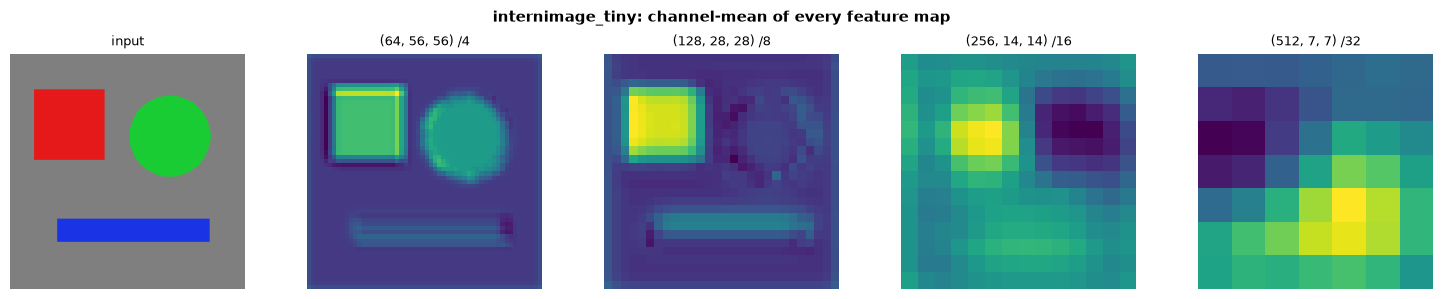

In [20]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [21]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [22]:
import sys

import torch

x = torch.randn(1, 3, 224, 224)

for name in ['internimage_tiny', 'internimage_small', 'internimage_base']:
    bb = build_vision_backbone(name, img_size=224)
    bb.eval()
    with torch.no_grad():
        out = bb(x)
    print(f'{name:20s}  embed={out.pooled_output.shape[-1]}')
    print(f'  feature_maps: {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  params: {bb.num_parameters():,}')
    print()

internimage_tiny      embed=512
  feature_maps: [(1, 64, 56, 56), (1, 128, 28, 28), (1, 256, 14, 14), (1, 512, 7, 7)]
  params: 26,411,504



internimage_small     embed=640
  feature_maps: [(1, 80, 56, 56), (1, 160, 28, 28), (1, 320, 14, 14), (1, 640, 7, 7)]
  params: 44,518,720



internimage_base      embed=896
  feature_maps: [(1, 112, 56, 56), (1, 224, 28, 28), (1, 448, 14, 14), (1, 896, 7, 7)]
  params: 87,123,008



## References

1. **[Primary]** Wang, W., et al. (2023). **InternImage: Exploring Large-Scale Vision Foundation Models with Deformable Convolutions**. *CVPR 2023*. https://arxiv.org/abs/2211.05778

2. Zhu, X., et al. (2019). **Deformable ConvNets v2 (DCNv2)**. *CVPR 2019*. https://arxiv.org/abs/1811.11168 — DCNv2 that DCNv3 improves upon.

3. Dai, J., et al. (2017). **Deformable Convolutional Networks (DCNv1)**. *ICCV 2017*. https://arxiv.org/abs/1703.06211 — Original deformable convolution.

4. Liu, Z., et al. (2021). **Swin Transformer**. *ICCV 2021*. — Transformer architecture that InternImage's block structure mirrors (pre-norm, [attention+FFN] structure → [DCNv3+FFN]).

5. He, K., et al. (2022). **Masked Autoencoders Are Scalable Vision Learners**. *CVPR 2022*. — MAE pretraining framework adapted for InternImage foundation model training.